# Pass danger — 2022 World Cup

**Question:** which passes really put the opponent in danger, and can we measure it reliably?

**Approach:** for every completed pass of the tournament, estimate the probability that the team shoots within the next 15 seconds (same possession), using only what is known *at the moment of the pass*: where it starts, where it ends, and the players' positions (StatsBomb 360 data).

This notebook presents the results. The full pipeline (download → features → model) is in `construire_donnees.py` and the `passes/` folder. French version of this notebook: `analyse.ipynb`.

| Step | File |
|---|---|
| StatsBomb download | `passes/donnees.py` |
| Features of each pass (geometry + 360) | `passes/variables.py` |
| Model, validation, importance | `passes/modele.py` |
| Interactive app | `app_passes.py` |


In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from passes.langue import EQUIPES_EN, MODELES_EN, PHASES_TOURNOI_EN, VARIABLES_EN, ZONES_EN


plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
BLEU, VERT, ROUGE, GRIS = "#1f8fbf", "#2fa37a", "#d9534f", "#8a94a6"

passes = pd.read_parquet("data/passes.parquet")
matchs = pd.read_parquet("data/matchs.parquet")
minutes = pd.read_parquet("data/minutes.parquet")
rapport = json.load(open("data/rapport_modele.json", encoding="utf-8"))

# English version: the data is stored in French, so team, stage, model and feature names are translated here
for col in ("equipe", "adversaire"):
    passes[col] = passes[col].replace(EQUIPES_EN)
minutes["equipe"] = minutes["equipe"].replace(EQUIPES_EN)
matchs[["domicile", "exterieur"]] = matchs[["domicile", "exterieur"]].replace(EQUIPES_EN)
matchs["phase"] = matchs["phase"].replace(PHASES_TOURNOI_EN)
for cle in ("resultats", "resultats_dernier_tiers"):
    rapport[cle] = {MODELES_EN.get(k, k): v for k, v in rapport[cle].items()}
rapport["modele_retenu"] = MODELES_EN.get(rapport["modele_retenu"], rapport["modele_retenu"])
rapport["importance"] = {VARIABLES_EN.get(k, k): v for k, v in rapport["importance"].items()}
for ligne in rapport["valeur_ajoutee"]["par_zone_et_elimines"]:
    ligne["zone"] = ZONES_EN.get(ligne["zone"], ligne["zone"])
# English column names for the tables shown below
COLONNES_EN = {"joueur": "player", "receveur": "receiver", "equipe": "team", "dist_but_fin": "end_dist_to_goal",
               "angle_but_fin": "end_shot_angle", "adv_elimines": "opponents_bypassed",
               "defenseurs_restants": "defenders_remaining", "derriere_defense": "behind_defence_m",
               "dist_adv_fin": "nearest_opponent_m", "tir_15s": "shot_15s", "but_15s": "goal_15s",
               "tres_dangereuses": "very_dangerous", "valeur_90_pts": "value_added_90_pts"}

print(f"{len(passes):,} completed passes with a 360 frame, {passes.match_id.nunique()} matches")
print(f"360 coverage: {rapport['couverture_360']:.0%} of completed passes")
print(f"Passes followed by a shot within 15 s: {passes.tir_15s.mean():.1%}")

47,329 completed passes with a 360 frame, 64 matches
360 coverage: 84% of completed passes
Passes followed by a shot within 15 s: 6.7%


## 1. The data

- **StatsBomb events**: every pass with its start point, end point, technique and phase of play.
- **StatsBomb 360**: at the moment of each action, the position of every player visible in the TV footage.
- Coordinates converted to **metres (105 × 68)**; the passing team always attacks to the right.

A few of the features built for each pass:

In [2]:
colonnes = ["joueur", "receveur", "equipe", "minute", "dist_but_fin", "angle_but_fin", "adv_elimines",
            "defenseurs_restants", "derriere_defense", "dist_adv_fin", "tir_15s"]
passes.sort_values("danger", ascending=False)[colonnes].head(8).round(1).rename(columns=COLONNES_EN)

,player,receiver,team,minute,end_dist_to_goal,end_shot_angle,opponents_bypassed,defenders_remaining,behind_defence_m,nearest_opponent_m,shot_15s
3681,Kaoru Mitoma,Ao Tanaka,Japan,50,1.2,145.399994,0,0,-0.2,2.0,True
2376,Thorgan Hazard,Romelu Lukaku,Belgium,89,3.2,100.099998,1,0,1.0,3.0,True
15035,Christian Eriksen,Andreas Christensen,Denmark,69,3.4,95.900002,0,0,0.6,2.7,True
36050,Vinícius Júnior,Raphinha,Brazil,46,4.4,78.099998,0,0,3.0,2.9,False
13567,Antoine Griezmann,Kylian Mbappé,France,85,3.5,93.400002,7,0,6.9,6.7,True
27345,César Montes,Henry Martín,Mexico,46,2.9,103.400002,4,0,1.4,2.0,True
36477,Raphinha,Bremer,Brazil,89,3.5,92.400002,0,0,0.0,1.3,True
40639,Abdelhamid Sabiri,Romain Saïss,Morocco,72,3.5,94.300003,7,0,1.4,2.0,True


## 2. Danger depends first and foremost on where the pass ends

Before any modelling, the shot frequency by distance to goal shows a very strong effect: this is the baseline to beat.

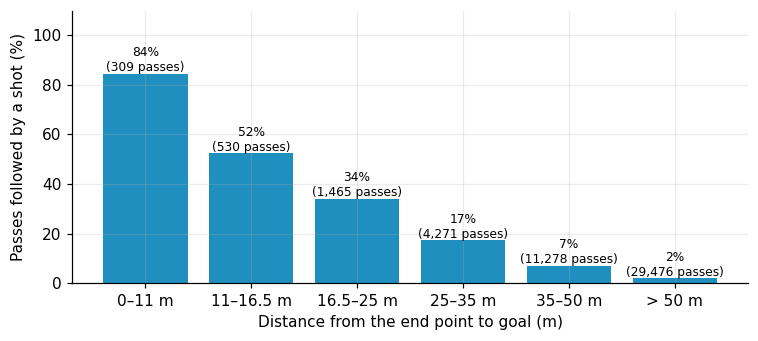

In [3]:
bornes = [0, 11, 16.5, 25, 35, 50, 120]
etiquettes = ["0–11 m", "11–16.5 m", "16.5–25 m", "25–35 m", "35–50 m", "> 50 m"]
tranches = pd.cut(passes["dist_but_fin"], bornes, labels=etiquettes)
taux = passes.groupby(tranches, observed=True)["tir_15s"].agg(["mean", "size"])

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(etiquettes, taux["mean"] * 100, color=BLEU)
for i, (t, n) in enumerate(zip(taux["mean"], taux["size"])):
    ax.text(i, t * 100 + 1, f"{t:.0%}\n({n:,} passes)", ha="center", fontsize=8)
ax.set_xlabel("Distance from the end point to goal (m)")
ax.set_ylabel("Passes followed by a shot (%)")
ax.set_ylim(0, taux["mean"].max() * 130)
plt.tight_layout()

## 3. 360 context: intuition is not enough

At equal distance, we would expect a pass that ends **in behind the last defender**, or with **few defenders between the ball and the goal**, to be followed by a shot more often. Let's look at passes ending between 16.5 and 30 m from goal:

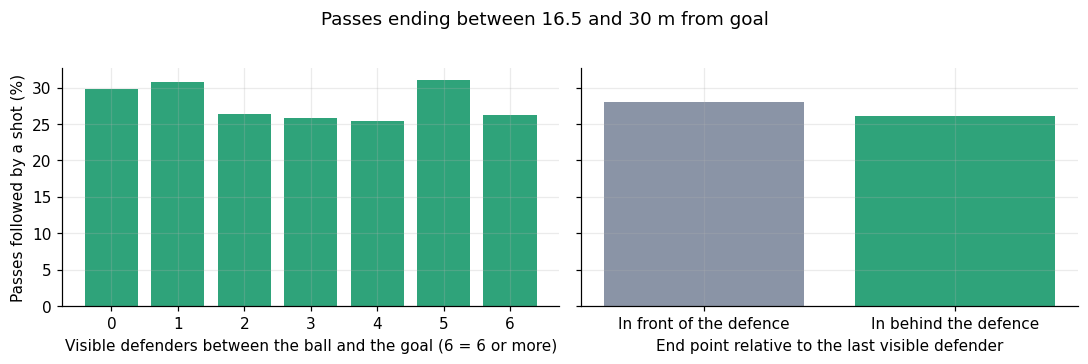

In [4]:
zone = passes[passes["dist_but_fin"].between(16.5, 30)]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)

restants = zone.groupby(zone["defenseurs_restants"].clip(upper=6))["tir_15s"].mean() * 100
axes[0].bar(restants.index.astype(str), restants.values, color=VERT)
axes[0].set_xlabel("Visible defenders between the ball and the goal (6 = 6 or more)")
axes[0].set_ylabel("Passes followed by a shot (%)")

dos = zone.groupby(zone["derriere_defense"] > 0)["tir_15s"].mean() * 100
axes[1].bar(["In front of the defence", "In behind the defence"], dos.values, color=[GRIS, VERT])
axes[1].set_xlabel("End point relative to the last visible defender")
fig.suptitle("Passes ending between 16.5 and 30 m from goal", y=1.02)
plt.tight_layout()

**The data does not confirm the intuition, at least not directly.** On their own, these indicators do not separate dangerous passes: the raw effects are weak and noisy. There are several possible reasons: a pass in behind the defence is often longer and harder to control, and defenders outside the camera's field of view are not counted.

This is why the contribution of 360 data is measured in the only reliable way: comparing, in validation, a model **with** and **without** these features (next section).

## 4. Model and validation

- **Target:** a shot by the same team, in the same possession, within 15 seconds.
- **Match-grouped cross-validation** (5 folds): a match is never in both the training and the test set. All probabilities used afterwards are out-of-sample predictions.
- **Comparison** with the first version of the project (a formula with hand-picked weights) and with simple baselines.
- Confidence intervals for the AUC gain are obtained by **bootstrapping over matches** (300 resamples).

In [5]:
lignes = []
for nom, m in rapport["resultats"].items():
    lignes.append({"Approach": nom, "AUC (all)": m["auc"],
                   "AUC (final third)": rapport["resultats_dernier_tiers"][nom]["auc"],
                   "Log loss": m.get("log_loss"), "Brier skill": m.get("brier_skill")})
tableau = pd.DataFrame(lignes).set_index("Approach")
print("Chosen model:", rapport["modele_retenu"])
print("Gain from 360 context:", rapport["gain_contexte_360"])
print("Gain vs previous formula:", rapport["gain_vs_ancienne_formule"])
tableau

Chosen model: Logistic regression
Gain from 360 context: {'gain': 0.0092, 'ic95': [0.0054, 0.0131]}
Gain vs previous formula: {'gain': 0.118, 'ic95': [0.1075, 0.1285]}


,AUC (all),AUC (final third),Log loss,Brier skill
Approach,,,,
Previous formula (hand-picked weights),0.7179,0.5831,NaN,NaN
Distance to goal only,0.8285,0.7424,NaN,NaN
Position only (no 360),0.8267,0.7484,0.18785,0.1962
Logistic regression,0.8359,0.7527,0.18558,0.2018
Gradient boosting,0.8342,0.7523,0.18594,0.2002


**Reading:**
- The previous formula is far behind, and close to random in the final third (where danger is decided).
- Distance to goal alone is a very strong baseline: position explains most of the danger.
- 360 context brings a **modest but significant** gain (the confidence interval does not include 0).
- Logistic regression is the chosen model: same accuracy as gradient boosting, better log loss, simpler to explain.

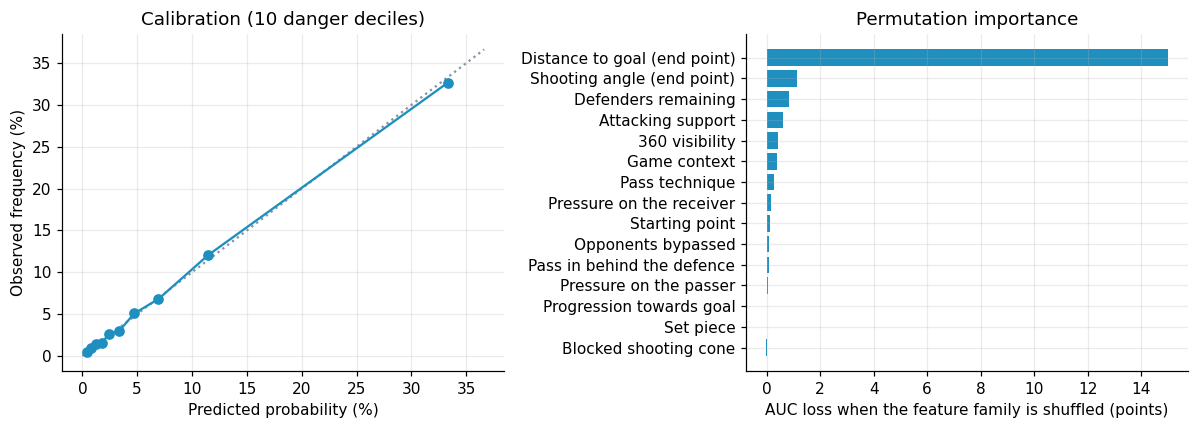

In [6]:
deciles = pd.DataFrame(rapport["deciles"])
importance = pd.Series(rapport["importance"]).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
lim = deciles[["proba_moyenne", "taux_observe"]].max().max() * 110
axes[0].plot([0, lim], [0, lim], ls=":", color=GRIS)
axes[0].plot(deciles["proba_moyenne"] * 100, deciles["taux_observe"] * 100, "o-", color=BLEU)
axes[0].set_xlabel("Predicted probability (%)")
axes[0].set_ylabel("Observed frequency (%)")
axes[0].set_title("Calibration (10 danger deciles)")

axes[1].barh(importance.index, importance.values * 100, color=BLEU)
axes[1].set_xlabel("AUC loss when the feature family is shuffled (points)")
axes[1].set_title("Permutation importance")
plt.tight_layout()

## 5. Value added: rewarding progression too

Danger measures **how close a shot is**. A line-breaking pass in midfield ends far from goal: it remains not very dangerous, even if it moves the team forward a lot.

To reward it, a second model estimates the shot probability **before the pass**, from the passer's situation alone (ball position, pressure, defenders between him and the goal, phase of play), without knowing the destination. Same target, same match-grouped validation.

> **value added = danger after the pass − shot probability before the pass** (in probability points)

It is zero on average: positive if the pass improves the situation, negative if it worsens it.

'Before the pass' model: Gradient boosting — AUC 0.7952
Average value added (points): 0.003 · share of positive passes: 36%
Correlation (Spearman) with opponents bypassed: {'danger': 0.373, 'valeur_ajoutee': 0.463}


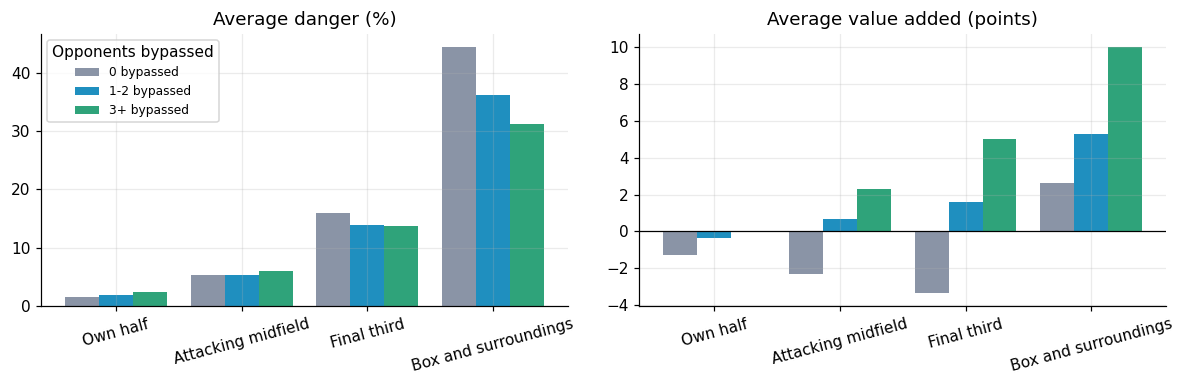

In [7]:
avant, va = rapport["valeur_avant"], rapport["valeur_ajoutee"]
print("'Before the pass' model:", avant["modele_retenu"], "— AUC", avant["resultats"][avant["modele_retenu"]]["auc"])
print("Average value added (points):", va["moyenne"], "· share of positive passes:", f"{va['part_positive']:.0%}")
print("Correlation (Spearman) with opponents bypassed:", va["correlation_adv_elimines"])

par_zone = pd.DataFrame(va["par_zone_et_elimines"])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharex=True)
largeur, zones = 0.27, list(dict.fromkeys(par_zone["zone"]))
for k, (niveau, couleur) in enumerate([("0", GRIS), ("1-2", BLEU), ("3+", VERT)]):
    sous = par_zone[par_zone["elimines"] == niveau].set_index("zone").loc[zones]
    x = np.arange(len(zones)) + (k - 1) * largeur
    axes[0].bar(x, sous["danger"], largeur, color=couleur, label=f"{niveau} bypassed")
    axes[1].bar(x, sous["valeur_ajoutee"], largeur, color=couleur)
axes[0].set_title("Average danger (%)")
axes[1].set_title("Average value added (points)")
axes[1].axhline(0, color="black", lw=0.8)
for ax in axes:
    ax.set_xticks(range(len(zones)), zones, rotation=15)
axes[0].legend(title="Opponents bypassed", fontsize=8)
plt.tight_layout()

**Reading:** raw danger ranked passes that bypass opponents poorly (in the final third, they were even *less* dangerous on average). Value added puts things back in order: in the final third, +5.0 points for 3 or more opponents bypassed against −3.4 for none; in attacking midfield, +2.3 against −2.3.

**Limitation:** in a team's own half, even a pass that bypasses 3 opponents adds almost nothing (+0.0), because the probability of a shot within 15 seconds remains very low there, before and after the pass. Valuing build-up play would require a longer-term target (for example, a shot before the end of the possession).

## 6. What it tells us about the tournament

### The most dangerous passers (open play, at least 270 minutes)

“Danger created” = sum of the shot probabilities of all of a player's passes, per 90 minutes.

In [8]:
jeu = passes[passes["type_passe"] == "Jeu courant"]
par_joueur = (jeu.groupby(["joueur_id", "joueur", "equipe"])
              .agg(passes=("danger", "size"), danger=("danger", "sum"),
                   valeur=("valeur_ajoutee", "sum"),
                   tres_dangereuses=("danger", lambda s: (s >= passes["danger"].quantile(0.95)).sum()))
              .reset_index()
              .merge(minutes.groupby("joueur_id")["minutes"].sum().reset_index(), on="joueur_id"))
par_joueur["danger_90"] = par_joueur["danger"] / par_joueur["minutes"] * 90
par_joueur["valeur_90_pts"] = par_joueur["valeur"] * 100 / par_joueur["minutes"] * 90  # in points
top = par_joueur[par_joueur["minutes"] >= 270].nlargest(15, "danger_90")
top[["joueur", "equipe", "minutes", "passes", "tres_dangereuses", "danger_90", "valeur_90_pts"]].round(2).rename(columns=COLONNES_EN)

,player,team,minutes,passes,very_dangerous,danger_90,value_added_90_pts
517,Pedri,Spain,389.02,369,24,7.58,23.09
184,Joshua Kimmich,Germany,303.43,195,18,5.93,136.46
573,Jamal Musiala,Germany,283.48,87,27,5.70,-21.97
249,Rodri,Spain,430.57,593,6,5.49,-60.76
5,Ángel Di María,Argentina,327.38,95,27,4.89,101.01
121,Jordi Alba,Spain,284.42,256,9,4.88,26.49
161,Lionel Messi,Argentina,791.23,249,56,4.34,69.84
116,Sergio Busquets,Spain,395.91,236,13,4.28,-44.01
154,Ousmane Dembélé,France,467.61,130,27,4.07,65.39
16,Kevin De Bruyne,Belgium,297.04,77,15,4.06,118.08


### Players who move the team forward: ranking by value added

The ranking changes: value added highlights players who improve the situation with their passes, not only those who play close to goal.

In [9]:
par_joueur[par_joueur["minutes"] >= 270].nlargest(15, "valeur_90_pts")[
    ["joueur", "equipe", "minutes", "passes", "danger_90", "valeur_90_pts"]].round(2).rename(columns=COLONNES_EN)

,player,team,minutes,passes,danger_90,value_added_90_pts
184,Joshua Kimmich,Germany,303.43,195,5.93,136.46
16,Kevin De Bruyne,Belgium,297.04,77,4.06,118.08
5,Ángel Di María,Argentina,327.38,95,4.89,101.01
179,Hirving Lozano,Mexico,281.06,30,2.77,89.18
161,Lionel Messi,Argentina,791.23,249,4.34,69.84
333,Raphinha,Brazil,338.70,85,3.36,66.75
154,Ousmane Dembélé,France,467.61,130,4.07,65.39
588,Alistair Johnston,Canada,300.10,95,2.07,58.60
117,Bruno Fernandes,Portugal,396.49,143,3.85,57.53
35,Thiago Silva,Brazil,424.29,277,2.42,56.16


### Danger created and conceded by team

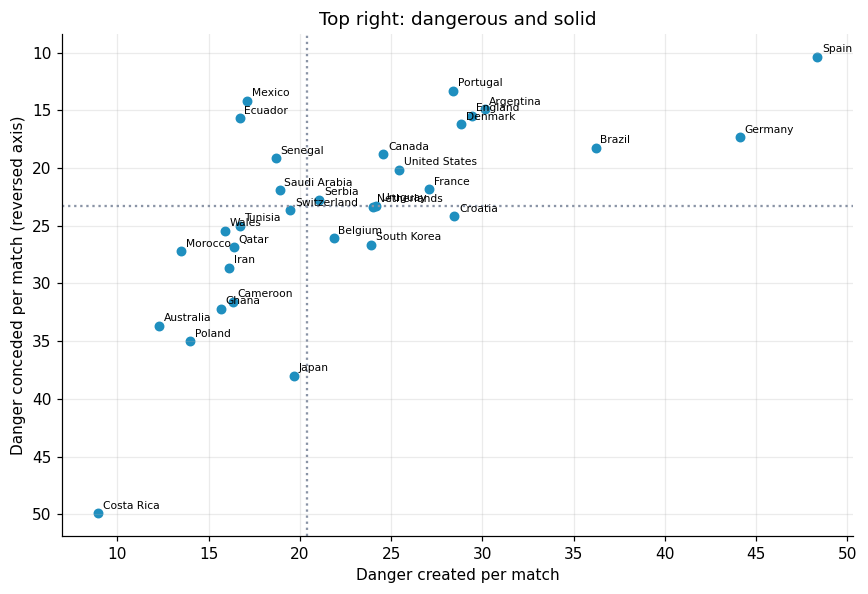

In [10]:
nb_matchs = pd.concat([matchs["domicile"], matchs["exterieur"]]).value_counts()
equipes = pd.DataFrame({"cree": jeu.groupby("equipe")["danger"].sum() / nb_matchs,
                        "concede": jeu.groupby("adversaire")["danger"].sum() / nb_matchs})

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(equipes["cree"], equipes["concede"], color=BLEU, s=30)
for nom, ligne in equipes.iterrows():
    ax.annotate(nom, (ligne["cree"], ligne["concede"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.axvline(equipes["cree"].median(), ls=":", color=GRIS)
ax.axhline(equipes["concede"].median(), ls=":", color=GRIS)
ax.invert_yaxis()
ax.set_xlabel("Danger created per match")
ax.set_ylabel("Danger conceded per match (reversed axis)")
ax.set_title("Top right: dangerous and solid")
plt.tight_layout()

### The most dangerous passes of the final

In [11]:
finale = matchs.loc[matchs["phase"] == "Final", "match_id"].item()
(passes[passes["match_id"] == finale]
 .nlargest(8, "danger")[["minute", "joueur", "receveur", "equipe", "danger", "tir_15s", "but_15s"]]
 .assign(danger=lambda d: (d["danger"] * 100).round(1))
 .rename(columns=COLONNES_EN))

,minute,player,receiver,team,danger,shot_15s,goal_15s
20638,35,Alexis MacAllister,Ángel Di María,Argentina,95.4,True,True
20897,67,Antoine Griezmann,Randal Kolo,France,91.8,True,False
21191,122,Gonzalo Montiel,Lautaro Martínez,Argentina,90.1,True,False
20840,59,Ángel Di María,Lionel Messi,Argentina,83.0,True,False
20637,35,Julián Álvarez,Alexis MacAllister,Argentina,82.4,True,True
21131,104,Lionel Messi,Lautaro Martínez,Argentina,79.6,True,False
21137,105,Marcos Acuña,Lautaro Martínez,Argentina,79.1,True,False
20515,16,Rodrigo De Paul,Lionel Messi,Argentina,75.5,True,False


## 7. Limitations and next steps

- **Players out of shot:** 360 data comes from TV footage; players outside the frame are not known. The “visible opponents” feature serves as a control.
- **A snapshot, not a film:** positions at the moment of the pass, not of the reception.
- **A single tournament:** testing the model trained here on Euro 2024 or Ligue 1 (also available in 360) would be the next validation.
- **Missed passes are not scored:** a risk model (probability of losing the ball) would complete the analysis, to judge a pass on its risk / danger trade-off.
- **Target:** “shot within 15 s” is simple and verifiable; a variant weighted by the shot's xG would also measure the quality of the chance.